In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
from pandas.plotting import scatter_matrix
from utils import save_fig # extra code – function to save the figures as high-res PNGs for the book

In [5]:
df = pd.read_csv("datasets/ice_cream_regression.csv")

In [13]:
x = df[["Temperature"]].values
y = df["Revenue"].values

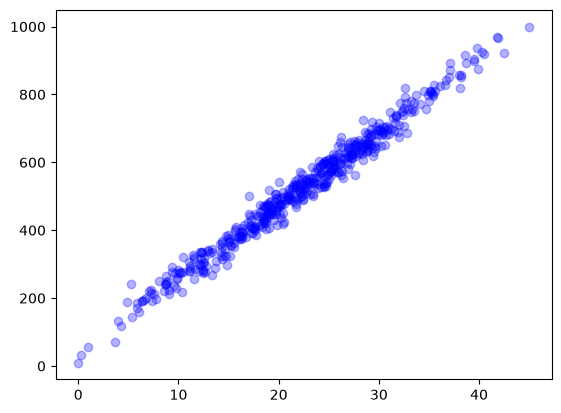

In [42]:
plt.plot(x, y, "o", color="blue", alpha=0.3)
plt.show()

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# -------- Train / Validation / Test split (70/15/15) --------
#X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
#X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)


X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

In [30]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
# -------- Evaluation function --------
def evaluate(model, X, y, dataset_name):
    y_pred = model.predict(X)
    r2 = r2_score(y, y_pred) #R-squared
    rmse = np.sqrt(mean_squared_error(y, y_pred)) #Root mean squared error
    mae = mean_absolute_error(y, y_pred) #Mean absolute error
    print(f"{dataset_name} -> R2: {r2:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}")

In [32]:
    #Model
    model = LinearRegression()
    
    # Train
    model.fit(X_train, y_train)
    
    # Evaluate
    evaluate(model, X_train, y_train, "Train")
    evaluate(model, X_val, y_val, "Validation")
    evaluate(model, X_test, y_test, "Test")

Train -> R2: 0.9799, RMSE: 24.7825, MAE: 19.5294
Validation -> R2: 0.9819, RMSE: 23.5427, MAE: 19.4169
Test -> R2: 0.9764, RMSE: 27.2895, MAE: 20.3146


In [35]:
y_pred_test = model.predict(X_test)
y_pred_val = model.predict(X_val)
y_pred_train = model.predict(X_train)

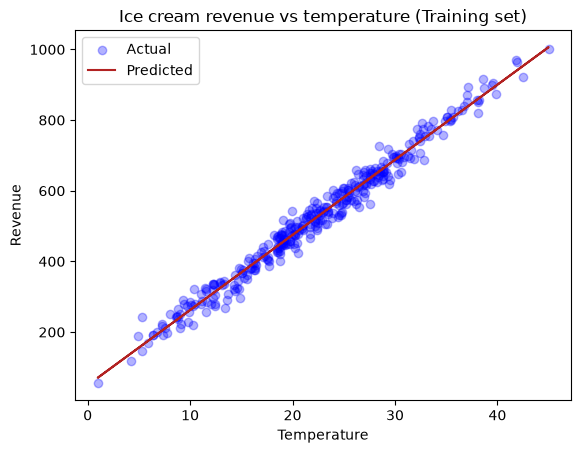

In [40]:
#prediction on training set
plt.scatter(X_train, y_train, color='blue', alpha=0.3, label='Actual')
plt.plot(X_train, y_pred_train, color='firebrick', label='Predicted')
plt.title('Ice cream revenue vs temperature (Training set)')
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.legend()
plt.show()


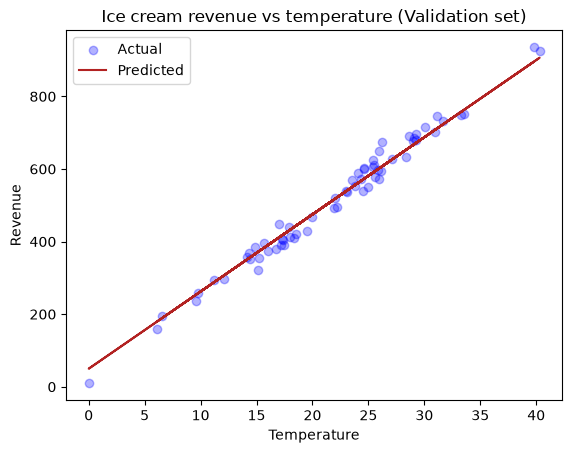

In [43]:
#prediction on validation set
plt.scatter(X_val, y_val, color='blue', alpha=0.3, label='Actual')
plt.plot(X_val, y_pred_val, color='firebrick', label='Predicted')
plt.title('Ice cream revenue vs temperature (Validation set)')
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.legend()
plt.show()

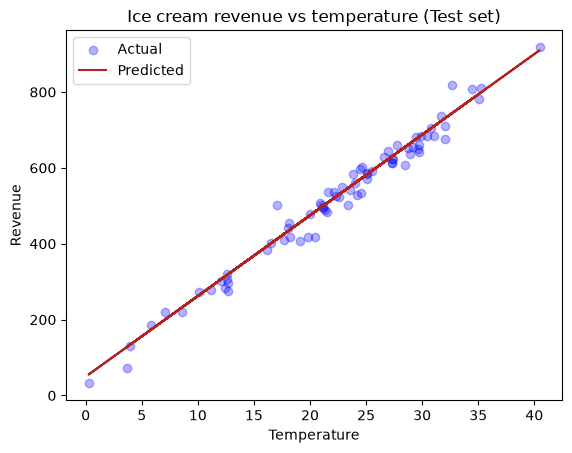

In [44]:
#prediction on test set
plt.scatter(X_test, y_test, color='blue', alpha=0.3, label='Actual')
plt.plot(X_test, y_pred_test, color='firebrick', label='Predicted')
plt.title('Ice cream revenue vs temperature (Test set)')
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.legend()

**Time spent, approx: 20min**